In [1]:
# ============================================================
# 01_Watershed.ipynb | Cell 1: imports, paths, parameters
# ============================================================
from pathlib import Path
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.windows import Window
from rasterio import features
from shapely.geometry import shape
import matplotlib.pyplot as plt
from whitebox import WhiteboxTools

# ---------- Paths ----------
cwd  = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "Notebooks" else cwd

INPUTS  = ROOT / "Inputs"
OUT_RAS = ROOT / "Outputs" / "Rasters"
OUT_VEC = ROOT / "Outputs" / "Vectors"
OUT_FIG = ROOT / "Outputs" / "Figures"
OUT_TAB = ROOT / "Outputs" / "Tables"
for p in (OUT_RAS, OUT_VEC, OUT_FIG, OUT_TAB):
    p.mkdir(parents=True, exist_ok=True)

DEM_PATH  = INPUTS / "kali44N.tif"
POUR_PATH = INPUTS / "kali_pourpoint.shp"

# ---------- Parameters ----------
CROP_KM       = 10      # inset from the valid-data bounding box on all four sides
SNAP_DIST_M   = 500     # outlet snap search distance (map units = metres in UTM)
CRS_EXPECTED  = 32644   # EPSG code for UTM 44N

# ---------- Whitebox ----------
wbt = WhiteboxTools()
wbt.set_working_dir(str(OUT_RAS))
wbt.set_verbose_mode(False)

print("Project root :", ROOT)
print("DEM exists   :", DEM_PATH.exists())
print("Outlet exists:", POUR_PATH.exists())
print("Whitebox     :", wbt.version().splitlines()[0])

Project root : D:\Watershed_Analysis
DEM exists   : True
Outlet exists: True
Whitebox     : WhiteboxTools v2.4.0 (c) Dr. John Lindsay 2017-2023


CRS       : EPSG:32644
Size      : (9601, 10127) | dtype: int16
Resolution: (29.512736202782968, 29.51273620278292)
Nodata    : 32767.0
Bounds    : BoundingBox(left=596436.6217184609, bottom=3042192.444736426, right=895312.101244044, top=3325544.225019345)
Valid cells  : 93,304,053 of 97,229,327 (96.0%)
Nodata cells : 3,925,274

Crop inset   : 10 km = 339 cells per side
Cropped size : (8923, 9448)
Nodata left inside crop: 0  <- should be 0

Outlet CRS   : EPSG:32644 | features: 1
Outlet inside cropped DEM: True


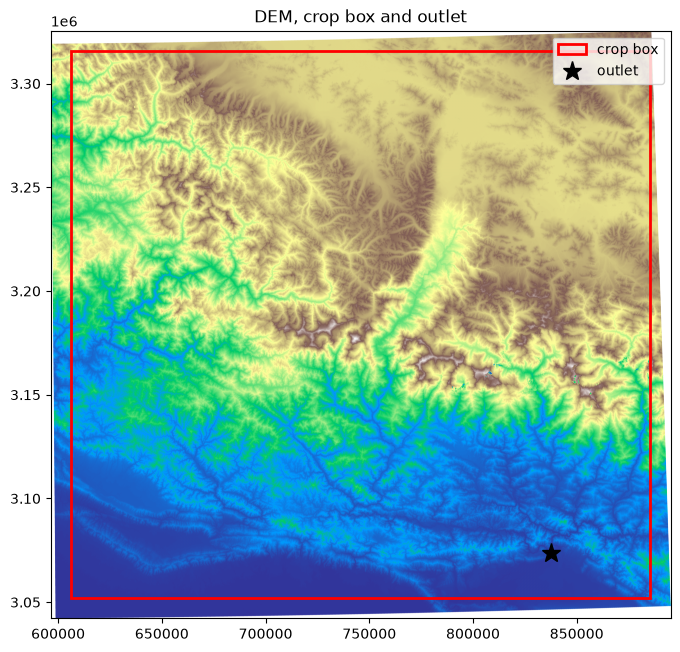

Saved: D:\Watershed_Analysis\Outputs\Rasters\dem_cropped.tif


In [2]:
# ============================================================
# Cell 2: inspect DEM + outlet, check nodata, crop edge strips
# ============================================================
with rasterio.open(DEM_PATH) as src:
    profile = src.profile.copy()
    dem     = src.read(1).astype("float32")
    nodata  = src.nodata
    crs     = src.crs
    res     = src.res
    bounds  = src.bounds
    transform = src.transform

print("CRS       :", crs)
print("Size      :", dem.shape, "| dtype:", profile["dtype"])
print("Resolution:", res)
print("Nodata    :", nodata)
print("Bounds    :", bounds)

if crs.to_epsg() != CRS_EXPECTED:
    print(f"WARNING: DEM CRS is not EPSG:{CRS_EXPECTED}")

# ---------- valid-data mask ----------
valid = np.isfinite(dem)
if nodata is not None:
    valid &= (dem != nodata)
else:
    print("WARNING: no nodata value set in the file; treating only NaN as nodata.")

print(f"Valid cells  : {valid.sum():,} of {valid.size:,} "
      f"({100*valid.mean():.1f}%)")
print(f"Nodata cells : {(~valid).sum():,}")

# ---------- bounding box of valid data ----------
rows = np.where(valid.any(axis=1))[0]
cols = np.where(valid.any(axis=0))[0]
r0, r1 = rows[0], rows[-1] + 1
c0, c1 = cols[0], cols[-1] + 1

# ---------- inset by CROP_KM ----------
n = int(round(CROP_KM * 1000 / res[0]))
r0c, r1c = r0 + n, r1 - n
c0c, c1c = c0 + n, c1 - n
assert r1c > r0c and c1c > c0c, "CROP_KM too large for this DEM"

win = Window(c0c, r0c, c1c - c0c, r1c - r0c)
dem_c = dem[r0c:r1c, c0c:c1c]
valid_c = valid[r0c:r1c, c0c:c1c]
transform_c = rasterio.windows.transform(win, transform)

left, top     = transform_c * (0, 0)
right, bottom = transform_c * (dem_c.shape[1], dem_c.shape[0])

print(f"\nCrop inset   : {CROP_KM} km = {n} cells per side")
print(f"Cropped size : {dem_c.shape}")
print(f"Nodata left inside crop: {(~valid_c).sum():,}  <- should be 0")

# ---------- outlet ----------
pp = gpd.read_file(POUR_PATH)
print("\nOutlet CRS   :", pp.crs, "| features:", len(pp))
if pp.crs != crs:
    pp = pp.to_crs(crs)
    print("Outlet reprojected to DEM CRS")
x, y = pp.geometry.iloc[0].x, pp.geometry.iloc[0].y
inside = (left <= x <= right) and (bottom <= y <= top)
print(f"Outlet inside cropped DEM: {inside}")

# ---------- save cropped DEM ----------
out_nodata = -9999.0
dem_out = np.where(valid_c, dem_c, out_nodata).astype("float32")
profile.update(height=dem_c.shape[0], width=dem_c.shape[1],
               transform=transform_c, nodata=out_nodata, dtype="float32",
               compress="lzw")
DEM_CROP = OUT_RAS / "dem_cropped.tif"
with rasterio.open(DEM_CROP, "w", **profile) as dst:
    dst.write(dem_out, 1)

# ---------- quick plot ----------
fig, ax = plt.subplots(figsize=(8, 8))
show = np.where(valid, dem, np.nan)
ax.imshow(show, extent=(bounds.left, bounds.right, bounds.bottom, bounds.top), cmap="terrain")
ax.add_patch(plt.Rectangle((left, bottom), right-left, top-bottom,
                           fill=False, ec="red", lw=2, label="crop box"))
ax.plot(x, y, "k*", ms=14, label="outlet")
ax.legend(); ax.set_title("DEM, crop box and outlet")
fig.savefig(OUT_FIG / "01_dem_crop_outlet.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", DEM_CROP)

Breach depressions           rc=0     8.4 s
D8 flow direction            rc=0     1.5 s
D8 flow accumulation         rc=0     3.7 s

Max accumulation: 27,268,840 cells = 23,751 km2


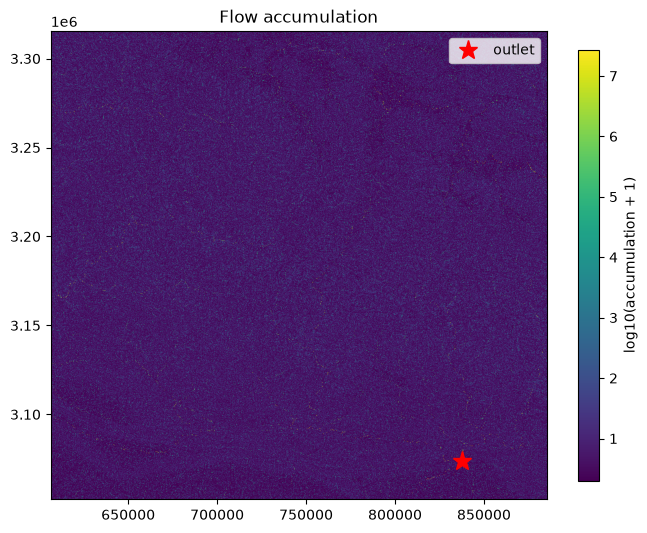

In [3]:
# ============================================================
# Cell 3: breach depressions, D8 flow direction, flow accumulation
# ============================================================
import time

DEM_COND = OUT_RAS / "dem_conditioned.tif"
FDIR     = OUT_RAS / "flow_direction.tif"
FACC     = OUT_RAS / "flow_accumulation.tif"

def run(label, func, *args, **kwargs):
    t0 = time.time()
    rc = func(*args, **kwargs)
    print(f"{label:<28} rc={rc}  {time.time()-t0:6.1f} s")
    assert rc == 0, f"{label} failed"

# 1) Condition: least-cost breaching, then fill whatever remains
run("Breach depressions",
    wbt.breach_depressions_least_cost,
    str(DEM_CROP), str(DEM_COND),
    dist=250,        # max breach search distance in cells (~3 km)
    fill=True)       # fill any depressions that could not be breached

# 2) D8 flow direction (whitebox encoding: powers of 2)
run("D8 flow direction",
    wbt.d8_pointer,
    str(DEM_COND), str(FDIR))

# 3) D8 flow accumulation, in number of upstream cells
run("D8 flow accumulation",
    wbt.d8_flow_accumulation,
    str(FDIR), str(FACC),
    out_type="cells", pntr=True)

# ---------- quick check ----------
with rasterio.open(FACC) as src:
    acc = src.read(1)
    acc_nd = src.nodata
acc = np.where(acc == acc_nd, np.nan, acc) if acc_nd is not None else acc
print(f"\nMax accumulation: {np.nanmax(acc):,.0f} cells "
      f"= {np.nanmax(acc)*res[0]*res[1]/1e6:,.0f} km2")

# ---------- figure (decimated for speed) ----------
step = 8
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(np.log10(acc[::step, ::step] + 1),
               extent=(left, right, bottom, top), cmap="viridis")
ax.plot(x, y, "r*", ms=14, label="outlet")
plt.colorbar(im, ax=ax, shrink=0.7, label="log10(accumulation + 1)")
ax.legend(); ax.set_title("Flow accumulation")
fig.savefig(OUT_FIG / "01_flow_accumulation.png", dpi=200, bbox_inches="tight")
plt.show()

Snap pour point              rc=0     0.7 s
Watershed                    rc=0     3.0 s

Watershed cells: 13,631,535
Watershed area : 11,873.1 km2
Snap shift     : 221 m (limit 500 m)
Accumulation at snapped outlet: 13,631,535 cells = 11,873.1 km2  (should be close to watershed area)
Watershed touches DEM edge: False  <- if True, basin is truncated


d:\miniconda\envs\kgflood\Lib\site-packages\rasterio\features.py:129: RuntimeWarning: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.
  yield from _shapes(source, mask, connectivity, transform)


Polygon area   : 11,873.1 km2 | perimeter 1,110.4 km


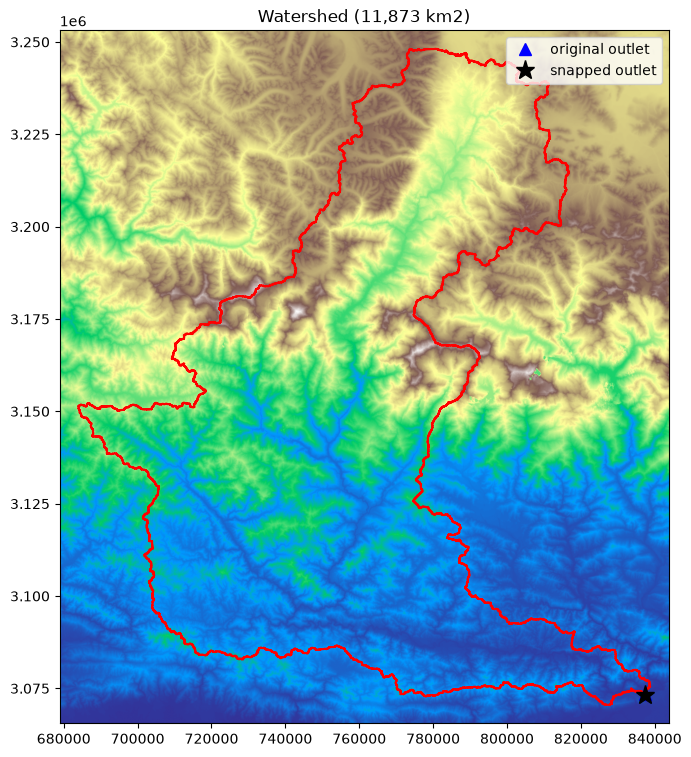

In [4]:
# ============================================================
# Cell 4: snap outlet, delineate watershed, boundary polygon
# ============================================================
SNAPPED_SHP = OUT_VEC / "outlet_snapped.shp"
WS_RAW      = OUT_RAS / "watershed_raw.tif"
WS_MASK     = OUT_RAS / "watershed_mask.tif"

# 1) Snap outlet to the highest-accumulation cell within SNAP_DIST_M
run("Snap pour point",
    wbt.snap_pour_points,
    str(POUR_PATH), str(FACC), str(SNAPPED_SHP), SNAP_DIST_M)

# 2) Watershed (whitebox D8 pointer encoding)
run("Watershed",
    wbt.watershed,
    str(FDIR), str(SNAPPED_SHP), str(WS_RAW),
    esri_pntr=False)

# ---------- read watershed, build clean mask ----------
with rasterio.open(WS_RAW) as src:
    ws = src.read(1)
    ws_nd = src.nodata
    ws_profile = src.profile.copy()

ws_mask = (ws > 0) & np.isfinite(ws)
if ws_nd is not None:
    ws_mask &= (ws != ws_nd)
del ws

n_cells = int(ws_mask.sum())
area_km2 = n_cells * res[0] * res[1] / 1e6
print(f"\nWatershed cells: {n_cells:,}")
print(f"Watershed area : {area_km2:,.1f} km2")

# ---------- checks: snap shift, outlet accumulation, edge contact ----------
sn = gpd.read_file(SNAPPED_SHP)
sx, sy = sn.geometry.iloc[0].x, sn.geometry.iloc[0].y
print(f"Snap shift     : {np.hypot(sx - x, sy - y):.0f} m (limit {SNAP_DIST_M} m)")

with rasterio.open(FACC) as src:
    r, c = src.index(sx, sy)
    acc_out = src.read(1, window=Window(c, r, 1, 1))[0, 0]
print(f"Accumulation at snapped outlet: {acc_out:,.0f} cells "
      f"= {acc_out*res[0]*res[1]/1e6:,.1f} km2  (should be close to watershed area)")

touches = (ws_mask[0, :].any() or ws_mask[-1, :].any() or
           ws_mask[:, 0].any() or ws_mask[:, -1].any())
print(f"Watershed touches DEM edge: {touches}  <- if True, basin is truncated")

# ---------- save clean mask (uint8) ----------
mask_profile = ws_profile.copy()
mask_profile.update(dtype="uint8", nodata=0, compress="lzw")
with rasterio.open(WS_MASK, "w", **mask_profile) as dst:
    dst.write(ws_mask.astype("uint8"), 1)

# ---------- polygonize on the watershed's bounding window only ----------
rr = np.where(ws_mask.any(axis=1))[0]
cc = np.where(ws_mask.any(axis=0))[0]
w = Window(cc[0], rr[0], cc[-1] - cc[0] + 1, rr[-1] - rr[0] + 1)
sub = ws_mask[rr[0]:rr[-1]+1, cc[0]:cc[-1]+1].astype("uint8")
sub_tf = rasterio.windows.transform(w, transform_c)

polys = [shape(g) for g, v in features.shapes(sub, mask=sub.astype(bool), transform=sub_tf) if v == 1]
gdf = gpd.GeoDataFrame({"area_km2": [area_km2]}, geometry=[gpd.GeoSeries(polys).union_all()], crs=crs)
gdf["area_km2"] = gdf.geometry.area / 1e6
gdf["perim_km"] = gdf.geometry.length / 1e3

gdf.to_file(OUT_VEC / "watershed_boundary.gpkg", driver="GPKG")
gdf.to_file(OUT_VEC / "watershed_boundary.shp")
print(f"Polygon area   : {gdf.area_km2.iloc[0]:,.1f} km2 | perimeter {gdf.perim_km.iloc[0]:,.1f} km")

# ---------- figure ----------
minx, miny, maxx, maxy = gdf.total_bounds
pad = 5000
with rasterio.open(DEM_COND) as src:
    win_p = rasterio.windows.from_bounds(minx-pad, miny-pad, maxx+pad, maxy+pad, src.transform)
    win_p = win_p.intersection(Window(0, 0, src.width, src.height))
    step = max(1, int(max(win_p.width, win_p.height) // 1500))
    dsub = src.read(1, window=win_p, out_shape=(int(win_p.height // step), int(win_p.width // step)))
    ext = rasterio.windows.bounds(win_p, src.transform)
dsub = np.where(dsub == -9999, np.nan, dsub)

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(dsub, extent=(ext[0], ext[2], ext[1], ext[3]), cmap="terrain")
gdf.boundary.plot(ax=ax, color="red", lw=1.5)
ax.plot(x, y, "b^", ms=9, label="original outlet")
ax.plot(sx, sy, "k*", ms=14, label="snapped outlet")
ax.legend(); ax.set_title(f"Watershed ({area_km2:,.0f} km2)")
fig.savefig(OUT_FIG / "01_watershed.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
# ============================================================
# Cell 5: watershed summary table + output inventory
# ============================================================
import pandas as pd

summary = pd.DataFrame([{
    "dem_file"          : DEM_PATH.name,
    "crs_epsg"          : crs.to_epsg(),
    "resolution_m"      : round(res[0], 3),
    "crop_inset_km"     : CROP_KM,
    "outlet_x_original" : x,
    "outlet_y_original" : y,
    "outlet_x_snapped"  : sx,
    "outlet_y_snapped"  : sy,
    "snap_shift_m"      : round(float(np.hypot(sx - x, sy - y)), 1),
    "snap_distance_m"   : SNAP_DIST_M,
    "watershed_cells"   : n_cells,
    "watershed_area_km2": round(area_km2, 2),
    "perimeter_km_raw"  : round(float(gdf.perim_km.iloc[0]), 2),
    "touches_dem_edge"  : bool(touches),
}])
summary.T.rename(columns={0: "value"}).to_csv(OUT_TAB / "01_watershed_summary.csv")
display(summary.T.rename(columns={0: "value"}))

# ---------- inventory ----------
expected = [
    OUT_RAS / "dem_cropped.tif",
    OUT_RAS / "dem_conditioned.tif",
    OUT_RAS / "flow_direction.tif",
    OUT_RAS / "flow_accumulation.tif",
    OUT_RAS / "watershed_mask.tif",
    OUT_VEC / "outlet_snapped.shp",
    OUT_VEC / "watershed_boundary.gpkg",
    OUT_VEC / "watershed_boundary.shp",
    OUT_FIG / "01_watershed.png",
    OUT_TAB / "01_watershed_summary.csv",
]
print(f"{'file':<32}{'exists':<8}{'size (MB)':>10}")
for p in expected:
    ok = p.exists()
    mb = p.stat().st_size / 1e6 if ok else 0
    print(f"{p.name:<32}{str(ok):<8}{mb:>10.1f}")

,value
dem_file,kali44N.tif
crs_epsg,32644
resolution_m,29.513
crop_inset_km,10
outlet_x_original,837422.987604
outlet_y_original,3073505.518608
outlet_x_snapped,837422.869182
outlet_y_snapped,3073284.112326
snap_shift_m,221.4
snap_distance_m,500


file                            exists   size (MB)
dem_cropped.tif                 True         139.5
dem_conditioned.tif             True         674.5
flow_direction.tif              True         168.7
flow_accumulation.tif           True         337.3
watershed_mask.tif              True           1.8
outlet_snapped.shp              True           0.0
watershed_boundary.gpkg         True           0.4
watershed_boundary.shp          True           0.4
01_watershed.png                True           2.0
01_watershed_summary.csv        True           0.0
